# 11 — v14 : où le pooling spatial regarde

v14 empile deux softmax (12 têtes chacun) :

1. **coupe** (`attn_score`) — quelle image parmi 72 tokens (notebook 10) ;
2. **spatial** (`spatial_score`) — où dans cette coupe, grille **7×7** (~32 px).

Les overlays dessinent un **carré rouge** sur chaque case 7×7 où le softmax spatial se concentre (masse ≥ 2× l’uniforme, jusqu’à ~50 % de la masse). Pas de carré = tête encore **diffuse** (GAP = v11).

`Neff` : 49 = GAP, ~15–25 = un peu piqué, &lt; 10 = une ou deux cases.

Défaut : subset v14, **gold 58**. Relancer le forward seulement si `agg` n’est plus en mémoire ; sinon relancer à partir du CAM moyen.

```text
python -X utf8 -m src.infer.inspect_spatial --config configs/kneenet_v14_crop130_subset.yaml
```

In [7]:
from __future__ import annotations

import os
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.infer.inspect_spatial import (
    UNIFORM_ENTROPY, UNIFORM_N, load_config,
    peakiness_table, plot_mean_cams, plot_same_slice, plot_top_slices, run,
)

CONFIG = ROOT / "configs" / "kneenet_v14_crop130_subset.yaml"
SPLIT = "gold"       # 58 études, labels vrais
MAX_STUDIES = None
N_EXAMPLES = 6

cfg = load_config(str(CONFIG))
OUT = ROOT / "checkpoints" / cfg["run_name"] / "spatial_inspect"
CKPT = ROOT / "checkpoints" / cfg["run_name"] / "best.pt"
if not CKPT.exists():
    CKPT = ROOT / "checkpoints" / cfg["run_name"] / "last.pt"
print("config", CONFIG.name)
print("ckpt  ", CKPT, "exists", CKPT.exists())
print("out   ", OUT)

config kneenet_v14_crop130_subset.yaml
ckpt   c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\best.pt exists True
out    c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\spatial_inspect


In [8]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
packed = run(
    cfg, CKPT, SPLIT, OUT, device,
    batch_size=int(cfg.get("batch_size") or 4),
    num_workers=2,
    max_studies=MAX_STUDIES,
    n_examples=N_EXAMPLES,
)
summary, agg = packed["summary"], packed["agg"]
print(
    f"{summary['model']}  epoch {summary['epoch']}  "
    f"val AUC {summary['val_macro_auc']}  "
    f"{summary['split']} n={agg['n_studies']}"
)

ckpt c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v14_crop130_frac025\best.pt
kneenet_v14 epoch 10 val AUC 0.8292234011134892 | split gold
series presentes dans les volumes : 13219 / 24371
58 etudes, batch 4
  4 etudes
  8 etudes
  12 etudes
  16 etudes
  20 etudes
  24 etudes
  28 etudes
  32 etudes
  36 etudes
  40 etudes
  44 etudes
  48 etudes
  52 etudes
  56 etudes
  58 etudes

=== pic spatial (pondere par attention-coupe) ===
          target  entropy   neff  max_p  uniforme         lecture
             ACL    3.539 34.443  0.122        49    un peu pique
             MCL    3.293 26.917  0.182        49    un peu pique
 Medial Meniscus    3.804 44.891  0.048        49 GAP (pas pique)
Lateral Meniscus    3.735 41.877  0.066        49 GAP (pas pique)
       Medial OA    3.821 45.641  0.035        49 GAP (pas pique)
      Lateral OA    3.853 47.116  0.032        49 GAP (pas pique)
           PF OA    3.837 46.403  0.032        49 GAP (pas pique)
        Effusion    3.758 

## Est-ce que le 7×7 s’est piqué ?

Entropie et `Neff` **pondérés par l’attention-coupe** : on ne juge le CAM que sur les slices que la tête utilise vraiment. Uniforme = `entropy 3.89`, `Neff 49`.

In [9]:
tbl = peakiness_table(agg)
display(tbl.style.format({
    "entropy": "{:.2f}",
    "neff": "{:.1f}",
    "max_p": "{:.1%}",
    "uniforme": "{:.0f}",
}))
print(f"uniforme 7×7 : entropy={UNIFORM_ENTROPY:.2f}  Neff={UNIFORM_N}")
n_gap = int((tbl.neff > 35).sum())
n_peak = int((tbl.neff <= 20).sum())
print(f"têtes encore GAP-like (Neff>35) : {n_gap}/12   piquées (Neff≤20) : {n_peak}/12")

,target,entropy,neff,max_p,uniforme,lecture
0,ACL,3.54,34.4,12.2%,49,un peu pique
1,MCL,3.29,26.9,18.2%,49,un peu pique
2,Medial Meniscus,3.80,44.9,4.8%,49,GAP (pas pique)
3,Lateral Meniscus,3.73,41.9,6.6%,49,GAP (pas pique)
4,Medial OA,3.82,45.6,3.5%,49,GAP (pas pique)
5,Lateral OA,3.85,47.1,3.2%,49,GAP (pas pique)
6,PF OA,3.84,46.4,3.2%,49,GAP (pas pique)
7,Effusion,3.76,42.9,5.3%,49,GAP (pas pique)
8,Synovitis,3.73,41.7,7.9%,49,GAP (pas pique)
9,Baker's,3.19,24.3,21.4%,49,un peu pique


uniforme 7×7 : entropy=3.89  Neff=49
têtes encore GAP-like (Neff>35) : 7/12   piquées (Neff≤20) : 2/12


## CAM moyen par plan et par cible

Carré rouge = case(s) au-dessus de 2× l’uniforme. Un blob **en bas / au bord** de la grille, surtout fracture / contusion, est le même signal que la coupe 0 du notebook 10 (raccourci FOV). Un blob **central** (Baker, MCL) est plus anatomique.

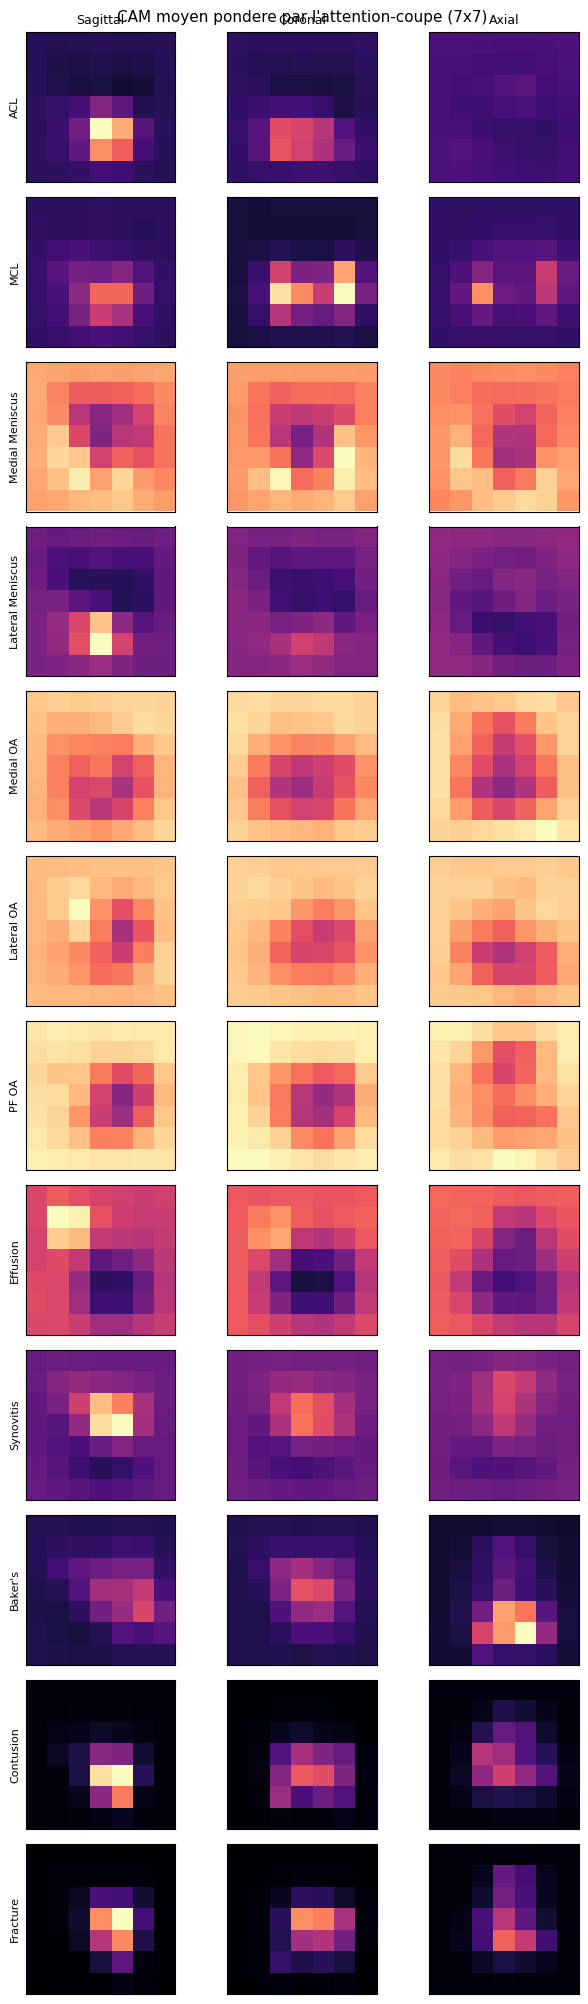

In [10]:
fig = plot_mean_cams(agg)
display(fig)
plt.close(fig)

## Top coupes + carrés rouges

Une ligne : la coupe, et un **carré rouge** (~32×32 px) là où `spatial_score` pique. Épaisseur ∝ masse de la case. « diffus » = softmax encore plat (pas de carré).

On priorise les **gold positifs**. Fracture / contusion / Baker / ACL : ce sont les têtes qui se sont vraiment localisées.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


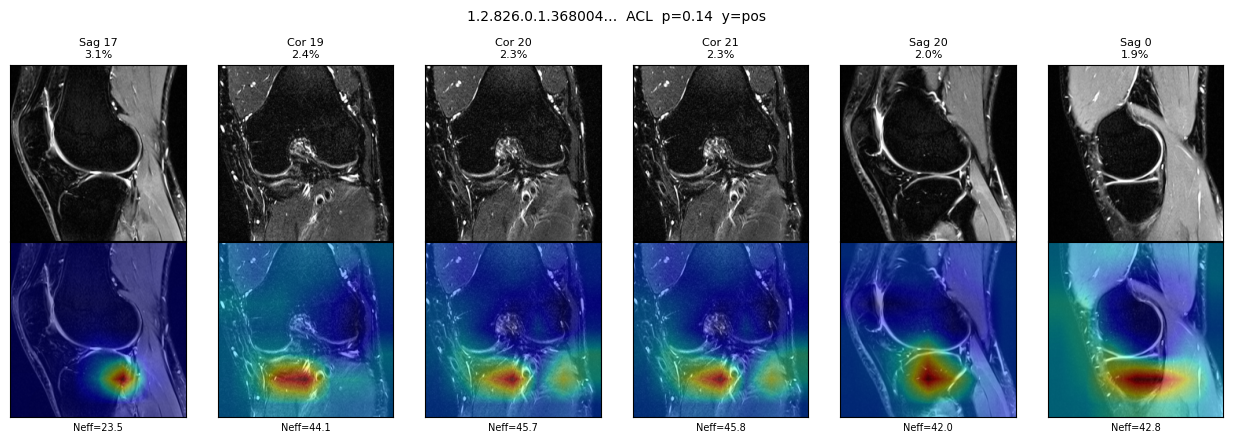

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


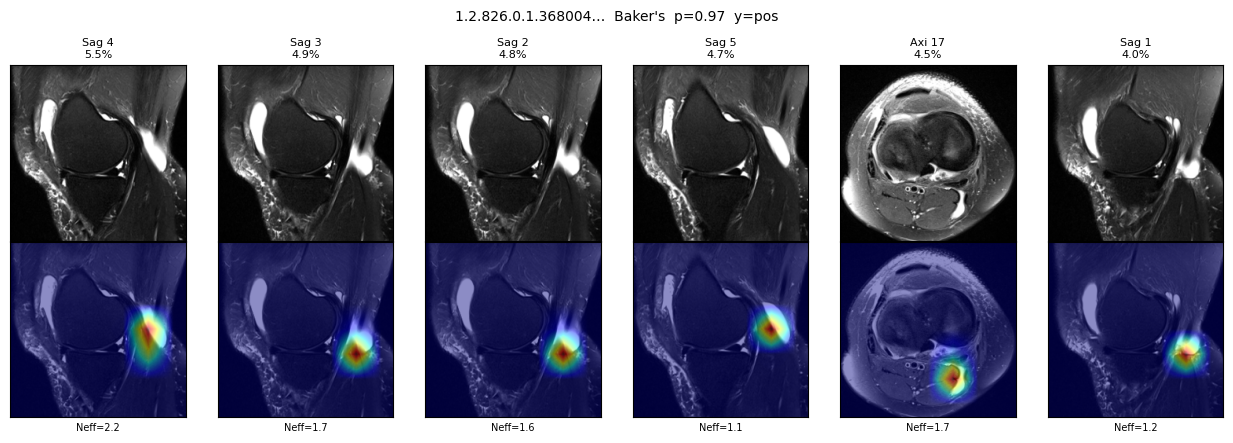

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


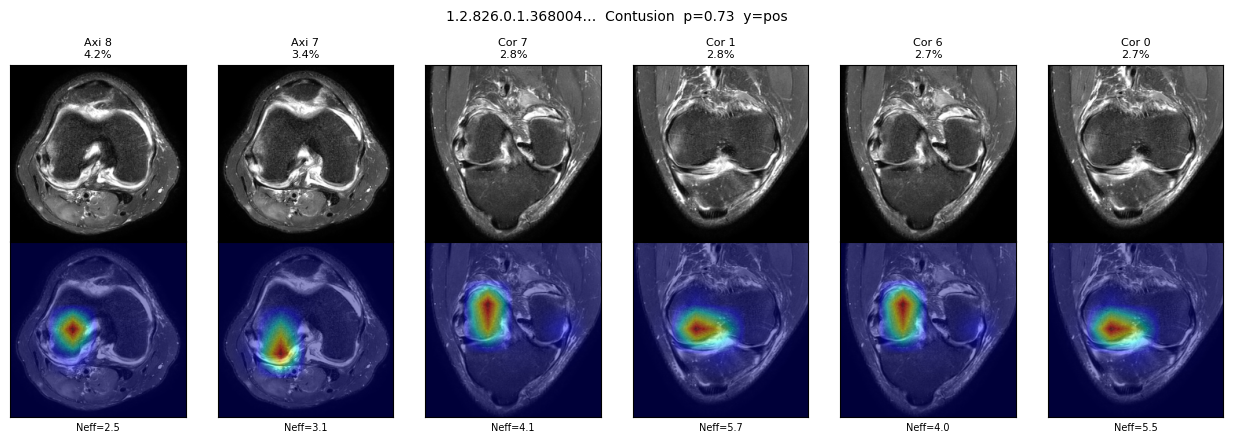

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


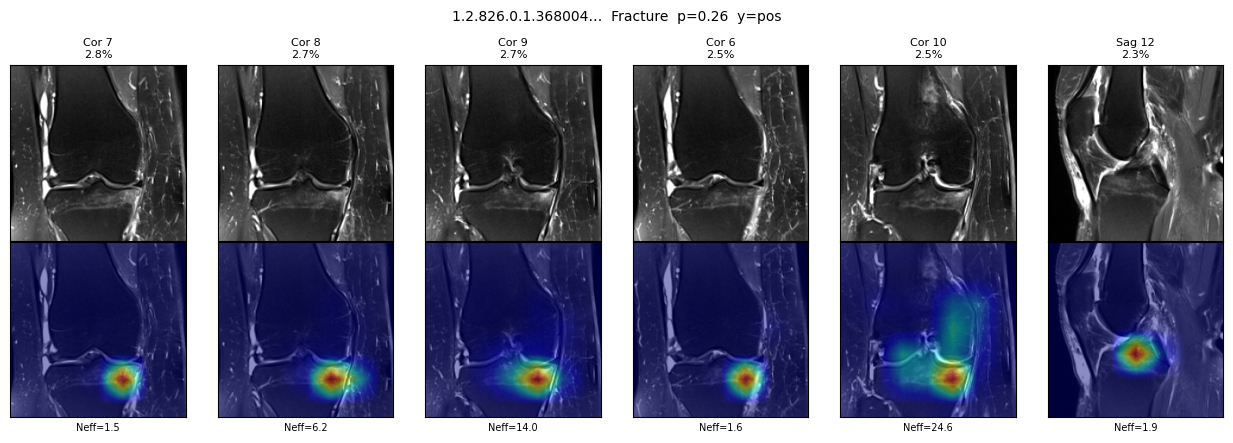

In [11]:
SHOW = ["ACL", "Baker's", "Contusion", "Fracture"]
planes = agg["planes"]
targets = agg["targets"]

for name in SHOW:
    if name not in targets:
        continue
    pool = agg["pos_examples"].get(name) or agg["examples"]
    if not pool:
        print(name, ": aucun exemple")
        continue
    ex = pool[0]
    fig = plot_top_slices(ex, name, targets, planes, k=6)
    display(fig)
    plt.close(fig)

## Même coupe, têtes différentes

Coupe max pour ACL, puis les carrés de ACL / Baker / fracture. Si les trois cadrent la même case, le spatial n’est pas spécifique. S’ils divergent (échancrure vs poplité vs bord), v14 fait ce pour quoi il a été conçu.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


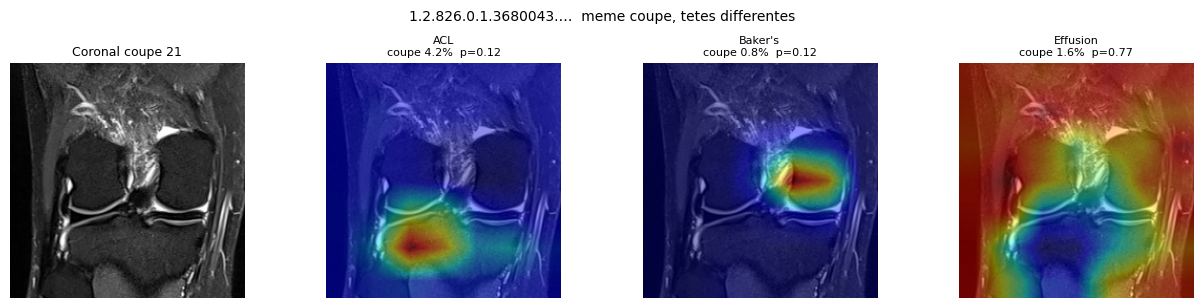

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.004313725978136063..1.000000011920929].


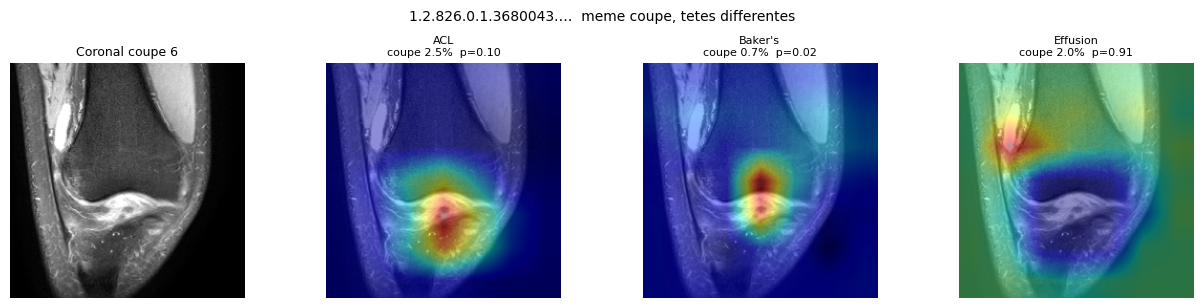

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


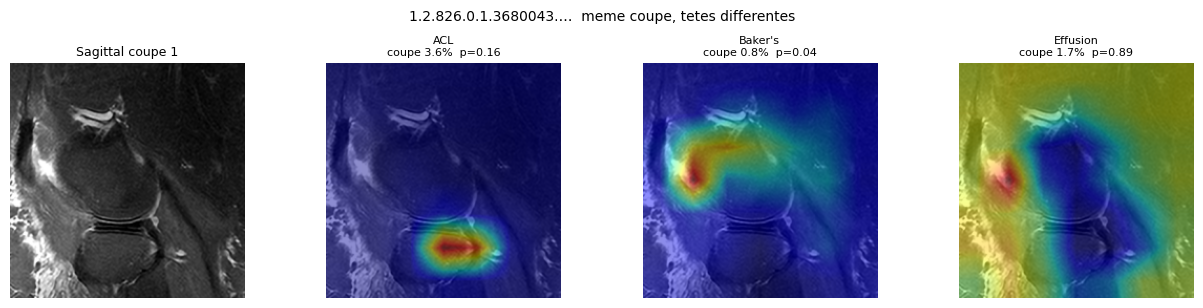

In [12]:
n_show = min(3, len(agg["examples"]))
for ex in agg["examples"][:n_show]:
    fig = plot_same_slice(ex, agg["targets"], agg["planes"])
    display(fig)
    plt.close(fig)

## Lecture (gold 58, v14 epoch 10)

Le pooling spatial **n’est pas uniforme**, mais il ne s’est piqué que sur **une minorité de têtes**.

| Têtes | Neff | max case | Lecture |
|---|---|---|---|
| Fracture, contusion | 6–8 | 46–50 % | **Très piqué** — souvent 1 case 7×7 |
| Baker, MCL | 24–27 | 18–21 % | Un peu piqué, plausible (poplité / médial) |
| ACL | 34 | 12 % | Léger, pas encore un vrai CAM |
| Ménisques, OA, épanchement, synovite | 42–47 | 3–8 % | **Encore un GAP** (v11) |

7/12 têtes n’utilisent pas le 7×7. Le gain subset vs v11 A+B (**val 0,829 vs 0,810**, **gold 0,867 vs 0,816**) vient surtout des têtes piquées (os / Baker / MCL), pas d’une localisation générale.

Le CAM moyen fracture / contusion se colle au **bas de la grille**, cohérent avec la coupe 0 coronale du notebook 10. Sur les overlays : si le carré rouge est **sur l’os** c’est du signal ; s’il est **sur le bord / l’air / le FOV** c’est un raccourci. Les OA « trou sombre au centre » ne sont pas une anti-attention savante : Neff ≈ 46, c’est juste du plat coloré.

## Suite

1. **Full-train v14** — le delta gold (+0,05) n’est pas du bruit de subset. Recette identique à v11 full (`crop130`, `train_frac: 1.0`).
2. **Vérifier les carrés fracture/contusion** (cellules overlays). Bord de FOV → ne pas « densifier » le 7×7 ; éventuellement une pénalité d’entropie pour empêcher le collapse à 1 case. Os cortical → le CAM sert, on garde v14 tel quel.
3. **Ne pas** attendre un gain ménisque / OA / épanchement de ce pooling : ces têtes sont restées GAP. Autre levier (labels, T1, RGB D) si on vise ces cibles.
4. **Ne pas** resserrer `BAND` ni dropper des coupes (notebook 10) : le spatial piqué *utilise* les bords.
5. Ablation utile plus tard : geler `spatial_score` à 0 (v14 = v11) vs appris, pour chiffrer le gain réel du 7×7.